## T-tests and Comparing Groups

### Learning Goals
* Compare two independent groups using Welch's $t$-test.
* Distinguish statistical significance from practical effect size.
* Inspect group distributions visually before interpreting test results.
* Understand the distinction between independent samples and paired study designs.

---

### 1. Example: Comparing Two Independent Groups

When comparing the means of two independent populations, the standard Student's $t$-test assumes equal population variances. However, **Welch's $t$-test** relaxes this assumption, making it the safer and more robust default choice for independent group comparisons:
$$
t = \frac{\bar{x}_1 - \bar{x}_2}{\sqrt{\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}}}
$$
]),

In [1]:
import numpy as np
from scipy import stats

# Sample scores for two groups
group_a = np.array([68, 72, 70, 65, 74, 69, 71, 67])
group_b = np.array([73, 76, 72, 78, 70, 75, 77, 74])

print(f"Mean A: {group_a.mean():.2f} | Mean B: {group_b.mean():.2f}")

# Perform Welch's t-test (equal_var=False)
test_result = stats.ttest_ind(group_a, group_b, equal_var=False)
print(test_result)

Mean A: 69.50 | Mean B: 74.38
TtestResult(statistic=np.float64(-3.5124344589622187), pvalue=np.float64(0.003475728383206607), df=np.float64(13.921027404758918))


### 2. Visualization and Estimating Differences

Numerical summaries and $p$-values should always be paired with visual inspections. Boxplots allow us to compare centers, spreads, and potential skewness across groups simultaneously.

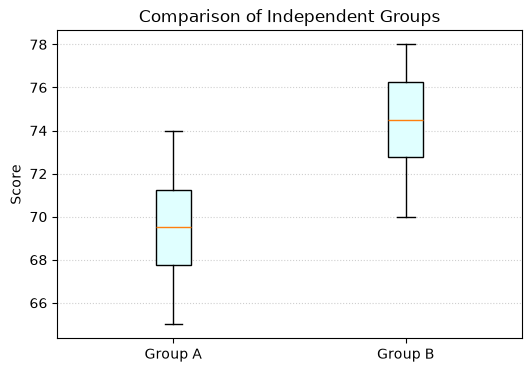

Difference in means (Group B - Group A): 4.88


In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.boxplot([group_a, group_b], tick_labels=["Group A", "Group B"], patch_artist=True, 
            boxprops=dict(facecolor='lightcyan'))
plt.ylabel("Score")
plt.title("Comparison of Independent Groups")
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.show()

mean_diff = group_b.mean() - group_a.mean()
print(f"Difference in means (Group B - Group A): {mean_diff:.2f}")

### 3. Study Design Matters

> **Key Design Rules:** 
> * **Welch's $t$-test** does not require equal population variances, but observations within and between groups *must* be independent.
> * **Paired Data:** If the observations are linked (e.g., pre-test and post-test measurements on the *same* individuals), a standard independent $t$-test is invalid. A **paired $t$-test** must be used instead to account for within-subject correlation.

---

### Exercises

Try each problem before running the verification code below:

1. Why might a statistically significant difference between two large groups be practically trivial?
2. When is a paired $t$-test more appropriate than an independent two-sample $t$-test?
3. What additional information should you report alongside a $p$-value when presenting group comparison results?

In [3]:
# --- Exercise Verification & Explanations ---
print("=== Exercise Solutions & Checks ===")

print("\n1. Statistically Significant vs. Practically Trivial:")
print("   - With a very large sample size, even a tiny, meaningless difference can yield a")
print("     p-value < 0.05. Practical importance requires evaluating the actual effect size.")

print("\n2. When to Use a Paired t-test:")
print("   - Appropriate when data points are naturally paired or dependent (e.g., before/after")
print("     interventions on the same participants, matched twin studies, or paired product tests).")

print("\n3. Beyond the P-value:")
print("   - You should always report point estimates (mean difference), confidence intervals")
print("     for the difference, effect size metrics (e.g., Cohen's d), and visualizations.")

=== Exercise Solutions & Checks ===

1. Statistically Significant vs. Practically Trivial:
   - With a very large sample size, even a tiny, meaningless difference can yield a
     p-value < 0.05. Practical importance requires evaluating the actual effect size.

2. When to Use a Paired t-test:
   - Appropriate when data points are naturally paired or dependent (e.g., before/after
     interventions on the same participants, matched twin studies, or paired product tests).

3. Beyond the P-value:
   - You should always report point estimates (mean difference), confidence intervals
     for the difference, effect size metrics (e.g., Cohen's d), and visualizations.
